 ## Importing Libraries and Loading Data

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data, skipping lines with parsing errors
df = pd.read_csv('products_asos.csv', on_bad_lines='skip')

# Print the number of rows loaded
print(f"data loaded: {len(df)}")
df.head()

data loaded: 30845


,url,name,size,category,price,color,sku,description,images
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,123650194.0,[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...


In [102]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30845 entries, 0 to 30844
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   url          30827 non-null  str    
 1   name         30827 non-null  str    
 2   size         30827 non-null  str    
 3   category     30827 non-null  str    
 4   price        30827 non-null  str    
 5   color        30827 non-null  str    
 6   sku          30827 non-null  float64
 7   description  30827 non-null  str    
 8   images       30827 non-null  str    
dtypes: float64(1), str(8)
memory usage: 55.1 MB


In [103]:
df.isnull().sum()

url            18
name           18
size           18
category       18
price          18
color          18
sku            18
description    18
images         18
dtype: int64

##  Data Cleaning

In [104]:
# Force price to be numeric and drop nulls
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

# Ensure description is a string
df['description'] = df['description'].astype(str)

## Extracting and Mapping Brands

In [105]:
# Define function to extract brand name from description
def get_brand(text):
    if 'by' in text:
        try:
            # Split by "by", take the second part, then split by space to get the first word
            return text.split('by')[1].strip().split(' ')[0]
        except:
            return 'unknown'
    return 'unknown'

# Apply function to create a temporary brand column
df['brand_row'] = df['description'].apply(get_brand)

df.head()

,url,name,size,category,price,color,sku,description,images,brand_row
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,123650194.0,[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...,StradivariusJacket


In [106]:
# Map extracted text to standard brand names
brand_map = {
    'New': 'New Look',
    'River': 'River Island',
    'Miss': 'Miss Selfridge',
    'TopshopWelcome': 'Top Shop'
}

# Apply the map and fill unmatched values with the original extracted text
df['Brand'] = df['brand_row'].map(brand_map).fillna(df['brand_row'])

## Filtering for High-Volume Brands

In [107]:
# Count brand occurrences
brand_counts = df['Brand'].value_counts()

# Keep only brands appearing more than 5 times
valid_brands = brand_counts[brand_counts > 5].index
df_clean = df[df['Brand'].isin(valid_brands)].copy()

print(df_clean['Brand'].value_counts().head(5))

Brand
ASOS              4844
Top Shop           711
New Look           511
River Island       474
Miss Selfridge     429
Name: count, dtype: int64


## Calculating Stockouts and Lost Revenue

In [114]:
# Function to calculate out-of-stock sizes and rate
def calculate_phantom_revenue(size_str):
    if not isinstance(size_str, str):
        return 0, 0.0

# Make text lowercase so capitalization does not matter
    size_str = size_str.lower()

    sizes = [size.strip() for size in size_str.split(',') if size.strip()]
    total_sizes = len(sizes)

    out_of_stock_count = sum(
        'out of stock' in size
        for size in sizes
    )

    stockout_rate = (
        out_of_stock_count / total_sizes
        if total_sizes > 0 else 0.0
    )

    return out_of_stock_count, stockout_rate

# Apply function (returns a list of tuples)
metrics = df_clean['size'].apply(lambda x: calculate_phantom_revenue(x))

# Assign the results back to separate columns using list comprehension
df_clean['Stockout_Count'] = [x[0] for x in metrics]
df_clean['Stockout_Rate'] = [x[1] for x in metrics]

# Calculate Lost Revenue
df_clean['Lost_Revenue'] = df_clean['price'] * df_clean['Stockout_Count']

# View the top 5 items losing the most revenue
cols = ['Brand', 'name', 'price', 'Stockout_Count', 'Lost_Revenue']

print(df_clean.sort_values(by="Lost_Revenue", ascending=False).head(5)[cols])

          Brand                                               name  price  \
2941    Barbour               Barbour Beadnell wax jacket in black  219.0   
21948  Top Shop  Topshop premium real leather collared zip thro...  260.0   
2715       ASOS  ASOS DESIGN premium real leather trench coat i...  220.0   
15584      ASOS  ASOS EDITION geo embellished fringe plunge mid...  250.0   
29838  Top Shop           Topshop Baggy co-ord jeans in green cord   50.0   

       Stockout_Count  Lost_Revenue  
2941                9        1971.0  
21948               7        1820.0  
2715                7        1540.0  
15584               6        1500.0  
29838              27        1350.0  


In [115]:
df.head()

,url,name,size,category,price,color,sku,description,images,brand_row,Brand
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New Look
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New Look
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New Look
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,126704571.0,[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...,New,New Look
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,123650194.0,[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...,StradivariusJacket,StradivariusJacket


## Aggregation and Quadrant Visualization

C:\Users\dell\AppData\Local\Temp\ipykernel_15692\3780763653.py:14: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


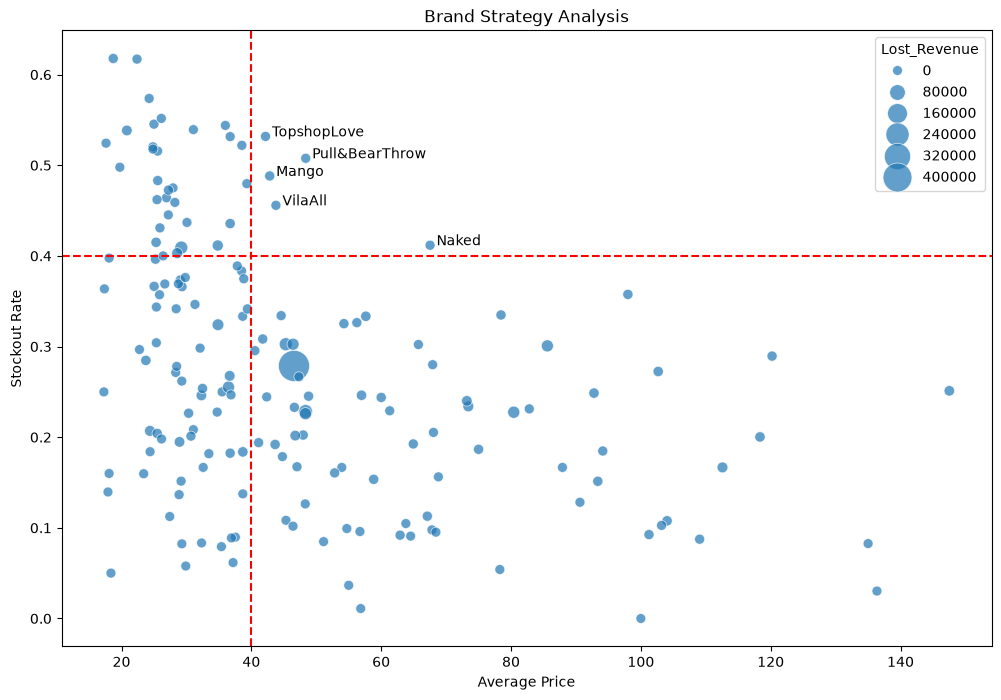

In [117]:
# Aggregate data by brand
brand_strategy = df_clean.groupby('Brand').agg({
    'price': 'mean',
    'Stockout_Rate': 'mean',
    'Lost_Revenue': 'sum',
    'name': 'count'
}).reset_index()

# Filter out brands with fewer than 10 total items
brand_strategy = brand_strategy[brand_strategy['name'] > 10]

# Plotting the Quadrant Scatter Plot
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=brand_strategy,
    x='price',
    y='Stockout_Rate', 
    size='Lost_Revenue',
    sizes=(50,500),
    alpha=0.7,
    palette='viridis'
    
)

# Identify 'winners' to label on the chart (Price > 40, Stockout Rate > 0.4)
winners = brand_strategy[
    (brand_strategy['price'] > 40) & 
    (brand_strategy['Stockout_Rate'] > 0.4)
    ]

# Add text labels for the winners
for i in range(len(winners)):
    plt.text(
        winners.iloc[i]['price']+1, 
        winners.iloc[i]['Stockout_Rate'], 
        winners.iloc[i]['Brand']
    )

# Add chart titles and labels
plt.title('Brand Strategy Analysis')
plt.xlabel('Average Price')
plt.ylabel('Stockout Rate')

# Add threshold lines to create the quadrants
plt.axvline(x=40, color='red', linestyle='--')
plt.axhline(y=0.4, color='red', linestyle='--') 

plt.show()